# HW2 : Convergence uniforme et limites de l'apprentissage
Dans ce devoir, j'étudie par simulation (Monte-Carlo) trois idées du cours : la **convergence uniforme**, le théorème **No-Free-Lunch** et le rôle du **biais inductif**. Je simule directement les lois de probabilité qui apparaissent dans les théorèmes, puis je compare les résultats expérimentaux aux quantités théoriques.

**Plan**
0. Paramètres et conventions
1. Partie I : simuler la convergence uniforme (tâches 1 à 5)
2. Partie II : simuler le No-Free-Lunch (tâches 6 à 8)
3. Partie III : introduire une connaissance a priori (tâches 9 et 10)
4. Conclusion (tâche 11)

## 0. Paramètres et conventions

| Paramètre | Valeur | Pourquoi ce choix |
|---|---|---|
| $\epsilon$ | 0.1 | précision demandée, assez grande pour que les probabilités d'échec passent sous $\delta$ avec des $m$ raisonnables |
| $\delta$ | 0.05 | confiance de 95 % |
| répétitions Monte-Carlo | 2 000 à 20 000 selon l'expérience | plus on estime une petite probabilité, plus il en faut ; écart-type d'une probabilité estimée $\le 0.5/\sqrt{R}$ |
| tailles d'échantillon $m$ | de 5 à 1000 | pour voir la décroissance exponentielle |
| tailles de classe $\lvert\mathcal H\rvert$ | 5, 10, 50, 100, 500 | valeurs suggérées par l'énoncé |
| tailles de domaine $N$ | 10, 20, 50, 100, 500 | pour voir l'effet du rapport $m/N$ (la partie III se concentre sur $N=100$ et $N=500$) |

Pour la graine, j'utilise `default_rng(42)` : tous les résultats sont reproductibles. Aucune bibliothèque de ML n'est utilisée, seulement `numpy` et `matplotlib`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)   # graine fixe : résultats reproductibles

EPS   = 0.1
DELTA = 0.05
K_LIST = [5, 10, 50, 100, 500]            # tailles de classe d'hypothèses (tâche 4)
M_GRID = [10, 20, 50, 100, 200, 300, 500, 750, 1000]   # tailles d'échantillon (tâches 1 à 4)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def hoeffding(m, eps=EPS):
    # borne de Hoeffding pour une hypothèse fixée : 2 exp(-2 m eps^2)
    return 2 * np.exp(-2 * np.asarray(m) * eps ** 2)

def union_bound(m, K, eps=EPS):
    # borne de convergence uniforme pour une classe finie : 2 K exp(-2 m eps^2), tronquée à 1
    return np.minimum(1.0, K * hoeffding(m, eps))

def large_dev(E, m, p, eps=EPS):
    # |E/m - p| > eps, écrit sur les entiers : |E - m p| > m eps.
    # Comparer E/m - p à eps en flottants est faux quand m*eps est entier (ex. m=10, p=0.3 :
    # 0.4 - 0.3 = 0.10000000000000003 > 0.1), alors que l'égalité exacte ne doit PAS compter.
    return np.round(np.abs(E - m * np.asarray(p)), 9) > np.round(m * eps, 9)

def exact_dev_single(m, p, eps=EPS):
    # valeur exacte de Pr[|E/m - p| > eps] pour E ~ Binomial(m, p) (somme finie)
    from math import lgamma, log, exp
    k = np.arange(m + 1)
    logpmf = np.array([lgamma(m + 1) - lgamma(j + 1) - lgamma(m - j + 1)
                       + j * log(p) + (m - j) * log(1 - p) for j in k])
    return float(np.exp(logpmf)[large_dev(k, m, p, eps)].sum())

# Partie I : simuler la convergence uniforme

**Modèle simplifié de l'énoncé.** Chaque hypothèse $h_j$ a une vraie erreur fixée $L_D(h_j) = p_j$. Sur un échantillon de taille $m$, le nombre d'erreurs est $E_j \sim \mathrm{Binomial}(m, p_j)$ et l'erreur empirique vaut $L_S(h_j) = E_j / m$. On peut donc simuler $L_S(h_j)$ directement, sans fabriquer de données.

## Tâche 1. L'erreur empirique comme variable aléatoire
Je fixe une hypothèse avec $p = 0.3$ et je simule $10^4$ échantillons pour plusieurs valeurs de $m$. Je trace la distribution de $L_S(h)$ et je compare sa moyenne à $p$, et son écart-type à la valeur théorique $\sqrt{p(1-p)/m}$ (propriété de la loi binomiale).

     m   moyenne L_S     p   écart-type emp.   sqrt(p(1-p)/m)
    10        0.2992  0.30            0.1450           0.1449
    50        0.3005  0.30            0.0652           0.0648
   200        0.2994  0.30            0.0324           0.0324
  1000        0.3002  0.30            0.0144           0.0145


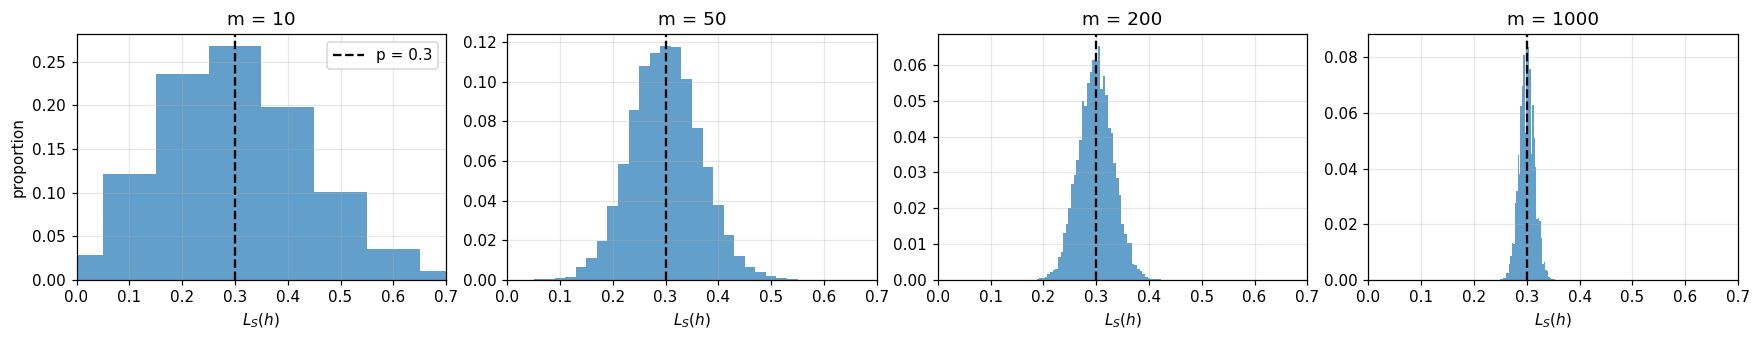

In [2]:
P_FIX  = 0.3
M_HIST = [10, 50, 200, 1000]
R_HIST = 10_000

fig, axes = plt.subplots(1, len(M_HIST), figsize=(16, 3.2), sharey=False)
print(f"{'m':>6}{'moyenne L_S':>14}{'p':>6}{'écart-type emp.':>18}{'sqrt(p(1-p)/m)':>17}")
for ax, m in zip(axes, M_HIST):
    LS = rng.binomial(m, P_FIX, size=R_HIST) / m
    print(f"{m:>6}{LS.mean():>14.4f}{P_FIX:>6.2f}{LS.std():>18.4f}{np.sqrt(P_FIX*(1-P_FIX)/m):>17.4f}")
    bins = np.arange(-0.5, m + 1.5) / m if m <= 200 else 40      # une barre par valeur possible k/m
    ax.hist(LS, bins=bins, weights=np.ones(R_HIST) / R_HIST, color="tab:blue", alpha=0.7)
    ax.axvline(P_FIX, color="k", ls="--", label=f"p = {P_FIX}")
    ax.set_xlim(0, 0.7); ax.set_title(f"m = {m}"); ax.set_xlabel(r"$L_S(h)$")
axes[0].set_ylabel("proportion"); axes[0].legend()
plt.tight_layout(); plt.show()

**Mon interprétation.** La moyenne empirique de $L_S(h)$ colle à $p = 0.3$ pour tous les $m$ (entre 0.2992 et 0.3005) : $L_S(h)$ est un estimateur **sans biais** de $L_D(h)$. Son écart-type empirique (0.145, 0.065, 0.032, 0.014) est quasiment égal à $\sqrt{p(1-p)/m}$ : il décroît en $1/\sqrt m$. Sur les histogrammes (une barre par valeur possible $k/m$), la distribution est large, discrète et un peu asymétrique à droite pour $m=10$ (seulement 11 valeurs possibles), puis se resserre en une cloche autour de $p$ : c'est la **concentration** de l'erreur empirique autour de l'erreur vraie quand $m$ augmente (loi des grands nombres).

## Tâche 2. Écart entre risque empirique et risque vrai (une seule hypothèse)
Pour chaque $m$, j'estime $\Pr[\lvert L_S(h) - L_D(h)\rvert > \epsilon]$ sur $2 \times 10^4$ répétitions et je compare à la borne de Hoeffding $2e^{-2m\epsilon^2}$. Je teste trois valeurs de $p$ : la borne ne dépend pas de $p$, mais la vraie probabilité, elle, en dépend (la variance de la loi binomiale est maximale pour $p = 0.5$). Comme $\Pr[\lvert L_S - p\rvert > \epsilon]$ est une somme finie de probabilités binomiales, je calcule aussi sa **valeur exacte** pour valider la simulation. Attention à un piège numérique : pour $m\epsilon$ entier (par exemple $m=10$), il faut comparer $\lvert E - mp\rvert$ à $m\epsilon$ **sur des entiers**, car en flottants $0.4 - 0.3 = 0.10000000000000003 > 0.1$ compterait à tort un écart exactement égal à $\epsilon$.

Pr[|L_S - p| > eps] : simulation / valeur exacte, et borne de Hoeffding
     m  p=0.1 sim   exact  p=0.3 sim   exact  p=0.5 sim   exact  Hoeffding
    10     0.0731  0.0702     0.2975  0.2996     0.3434  0.3437     1.0000
    20     0.0440  0.0432     0.2201  0.2204     0.2571  0.2632     1.0000
    50     0.0084  0.0094     0.0861  0.0880     0.1206  0.1189     0.7358
   100     0.0007  0.0008     0.0228  0.0214     0.0344  0.0352     0.2707
   200     0.0001  0.0000     0.0018  0.0015     0.0036  0.0036     0.0366
   300     0.0000  0.0000     0.0001  0.0001     0.0003  0.0004     0.0050
   500     0.0000  0.0000     0.0000  0.0000     0.0000  0.0000     0.0001
   750     0.0000  0.0000     0.0000  0.0000     0.0000  0.0000     0.0000
  1000     0.0000  0.0000     0.0000  0.0000     0.0000  0.0000     0.0000


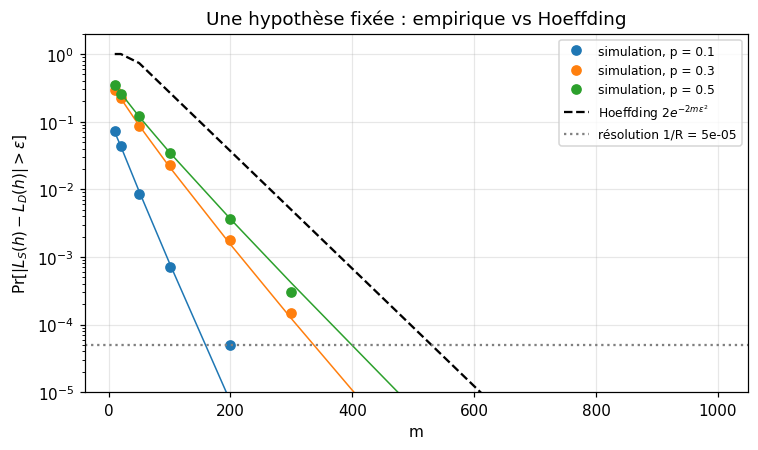

In [3]:
R2 = 20_000
P_TEST = [0.1, 0.3, 0.5]

def prob_dev_single(p, m, eps=EPS, R=R2):
    E = rng.binomial(m, p, size=R)
    return np.mean(large_dev(E, m, p, eps))

res2 = {p: np.array([prob_dev_single(p, m) for m in M_GRID]) for p in P_TEST}
ex2  = {p: np.array([exact_dev_single(m, p) for m in M_GRID]) for p in P_TEST}   # valeurs exactes (loi binomiale)
bound2 = hoeffding(M_GRID)

print("Pr[|L_S - p| > eps] : simulation / valeur exacte, et borne de Hoeffding")
print(f"{'m':>6}" + "".join(f"{'p='+str(p)+' sim':>11}{'exact':>8}" for p in P_TEST) + f"{'Hoeffding':>11}")
for i, m in enumerate(M_GRID):
    print(f"{m:>6}" + "".join(f"{res2[p][i]:>11.4f}{ex2[p][i]:>8.4f}" for p in P_TEST) + f"{min(1, bound2[i]):>11.4f}")

fig, ax = plt.subplots(figsize=(7, 4.2))
for p in P_TEST:
    y = np.where(res2[p] > 0, res2[p], np.nan)          # les zéros ne se tracent pas en échelle log
    ax.semilogy(M_GRID, y, "o", label=f"simulation, p = {p}")
    ax.semilogy(M_GRID, np.where(ex2[p] > 0, ex2[p], np.nan), "-", color=ax.lines[-1].get_color(), lw=1)
ax.semilogy(M_GRID, np.minimum(1, bound2), "k--", label=r"Hoeffding $2e^{-2m\epsilon^2}$")
ax.axhline(1 / R2, color="gray", ls=":", label=f"résolution 1/R = {1/R2:.0e}")
ax.set_xlabel("m"); ax.set_ylabel(r"$\Pr[|L_S(h) - L_D(h)| > \epsilon]$"); ax.set_ylim(1e-5, 2)
ax.set_title("Une hypothèse fixée : empirique vs Hoeffding"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Mon interprétation.**
- La simulation colle à la **valeur exacte** (somme binomiale) : par exemple pour $p=0.5$, $m=100$, 0.0344 simulé contre 0.0352 exact. Les plus gros écarts (0.006 à $m=20$) restent de l'ordre de deux écarts-types Monte-Carlo (environ 0.003 avec $2\times10^4$ répétitions). Cela valide le code.
- La probabilité de déviation $>\epsilon$ décroît très vite avec $m$ : pour $p=0.5$, 0.34 à $m=10$, 0.035 à $m=100$, 0.0004 à $m=300$. C'est bien une décroissance exponentielle.
- Elle est **toujours sous la borne de Hoeffding**, mais la borne est **conservative** : à $m=100$, 0.27 contre 0.035 (environ 8 fois plus grande). Pour $m \le 20$ la borne vaut plus de 1, donc elle ne dit rien. Elle ne tient pas compte de la variance et vaut pour tout $p$ (pire cas).
- La probabilité augmente bien avec la variance : tant que les probabilités ne sont pas nulles à l'arrondi (jusqu'à $m=300$), $p=0.1$ est plus faible que $p=0.3$, elle-même plus faible que $p=0.5$ (pire cas), ce que Hoeffding ignore puisque sa borne ne dépend pas de $p$.
- Les courbes exactes ne sont pas parfaitement lisses pour les petits $m$ : $L_S$ ne prend que des valeurs multiples de $1/m$, donc l'événement $\lvert E - mp\rvert > m\epsilon$ change par sauts. De plus, un écart **exactement égal** à $\epsilon$ (par exemple $m=10$, $p=0.3$, $E=4$) n'est pas compté, car l'inégalité est stricte. Une première version de mon code comparait $E/m - p$ à $\epsilon$ en flottants et comptait à tort certains de ces cas (0.4999 au lieu de 0.2996 pour $p=0.3$, $m=10$) ; la comparaison sur entiers corrige ce défaut.

## Tâche 3. D'une hypothèse à la convergence uniforme
Je prends une classe de $K = 50$ hypothèses, avec des risques vrais $p_j$ tirés une fois pour toutes dans $[0.05, 0.95]$. Pour chaque échantillon simulé je calcule les $K$ risques empiriques, puis $\Delta_S = \max_j \lvert L_S(h_j) - p_j\rvert$, et j'estime $\Pr[\Delta_S > \epsilon]$. Je compare à la borne de l'union $2Ke^{-2m\epsilon^2}$ (tronquée à 1).

Les $K$ erreurs empiriques sont ici **indépendantes** (chaque $E_j$ est simulée séparément), ce qui est une simplification par rapport à un vrai apprentissage où elles dépendent du même échantillon.

     m  Pr[Delta>eps]  borne 2K exp  1 hyp. (p=.5)
    10         1.0000        1.0000         0.3362
    20         1.0000        1.0000         0.2657
    50         0.9956        1.0000         0.1164
   100         0.7122        1.0000         0.0364
   200         0.0944        1.0000         0.0043
   300         0.0112        0.2479         0.0002
   500         0.0004        0.0045         0.0000
   750         0.0000        0.0000         0.0000
  1000         0.0000        0.0000         0.0000


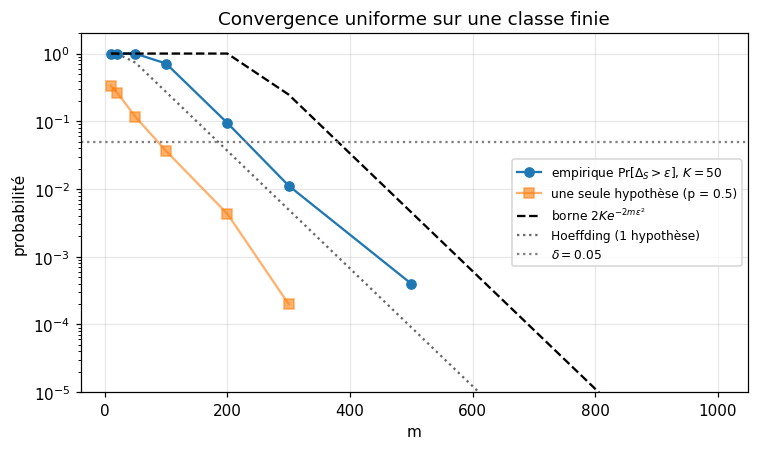

In [4]:
R3 = 5_000
K3 = 50
p3 = rng.uniform(0.05, 0.95, size=K3)

def prob_uniform_dev(p, m, eps=EPS, R=R3):
    # p : vecteur des K risques vrais ; renvoie Pr[max_j |L_S(h_j) - p_j| > eps]
    E = rng.binomial(m, p, size=(R, len(p)))
    return np.mean(large_dev(E, m, p, eps).any(axis=1))      # Delta_S > eps  <=>  au moins une hypothèse dévie

res3 = np.array([prob_uniform_dev(p3, m) for m in M_GRID])
single3 = np.array([prob_dev_single(0.5, m) for m in M_GRID])

print(f"{'m':>6}{'Pr[Delta>eps]':>15}{'borne 2K exp':>14}{'1 hyp. (p=.5)':>15}")
for i, m in enumerate(M_GRID):
    print(f"{m:>6}{res3[i]:>15.4f}{union_bound(m, K3):>14.4f}{single3[i]:>15.4f}")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.semilogy(M_GRID, np.where(res3 > 0, res3, np.nan), "o-", label=fr"empirique $\Pr[\Delta_S>\epsilon]$, $K={K3}$")
ax.semilogy(M_GRID, np.where(single3 > 0, single3, np.nan), "s-", alpha=0.6, label="une seule hypothèse (p = 0.5)")
ax.semilogy(M_GRID, union_bound(M_GRID, K3), "k--", label=r"borne $2Ke^{-2m\epsilon^2}$")
ax.semilogy(M_GRID, np.minimum(1, hoeffding(M_GRID)), "k:", alpha=0.6, label="Hoeffding (1 hypothèse)")
ax.axhline(DELTA, color="gray", ls=":", label=fr"$\delta={DELTA}$")
ax.set_xlabel("m"); ax.set_ylabel("probabilité"); ax.set_ylim(1e-5, 2)
ax.set_title("Convergence uniforme sur une classe finie"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Mon interprétation.** Contrôler **toutes** les hypothèses en même temps est plus difficile que d'en contrôler une seule : à $m=100$, $\Pr[\Delta_S>\epsilon] = 0.71$ pour la classe de 50 hypothèses, contre 0.036 pour une seule ; à $m=200$, 0.094 contre 0.004. Il faut attendre $m \approx 300$ pour que la probabilité passe sous $\delta$ (0.011).

La borne de l'union $2Ke^{-2m\epsilon^2}$ est **valide** à tous les $m$ (0.25 contre 0.011 à $m=300$, 0.0045 contre 0.0004 à $m=500$) mais **conservative** : elle vaut 1 (information nulle) jusqu'à $m=200$ alors que la vraie probabilité tombe déjà à 0.09. Cela vient de deux choses : l'union bound compte les mauvais événements comme s'ils étaient disjoints (il les additionne), et la borne de Hoeffding est elle-même pessimiste. Ici les erreurs sont indépendantes, ce qui est plutôt le cas où l'union bound est le moins mauvais.

## Tâche 4. Effet de la taille de la classe d'hypothèses
Je fixe $\epsilon = 0.1$ et je refais l'expérience pour $\lvert\mathcal H\rvert \in \{5, 10, 50, 100, 500\}$ (risques $p_j$ tirés dans $[0.05, 0.95]$ pour chaque taille). Je trace $\Pr[\Delta_S > \epsilon]$ en fonction de $m$ avec la borne théorique en pointillés.

     m      K=5     K=10     K=50    K=100    K=500
    10    0.960    0.998    1.000    1.000    1.000
    20    0.834    0.966    1.000    1.000    1.000
    50    0.468    0.642    0.994    1.000    1.000
   100    0.164    0.190    0.740    0.888    1.000
   200    0.013    0.019    0.103    0.176    0.619
   300    0.000    0.002    0.014    0.018    0.094
   500    0.000    0.000    0.000    0.001    0.002
   750    0.000    0.000    0.000    0.000    0.000
  1000    0.000    0.000    0.000    0.000    0.000


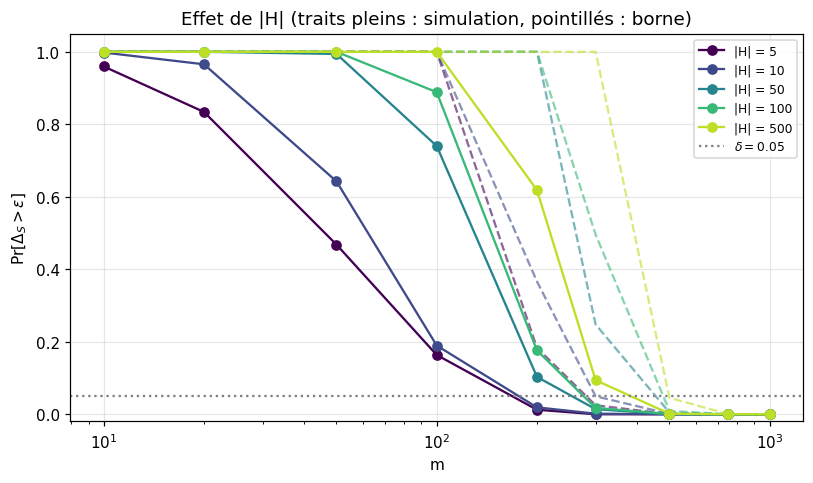

In [5]:
R4 = 2_000
p_by_K = {K: rng.uniform(0.05, 0.95, size=K) for K in K_LIST}
res4 = {K: np.array([prob_uniform_dev(p_by_K[K], m, R=R4) for m in M_GRID]) for K in K_LIST}

print(f"{'m':>6}" + "".join(f"{'K='+str(K):>9}" for K in K_LIST))
for i, m in enumerate(M_GRID):
    print(f"{m:>6}" + "".join(f"{res4[K][i]:>9.3f}" for K in K_LIST))

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for K, c in zip(K_LIST, plt.cm.viridis(np.linspace(0, 0.9, len(K_LIST)))):
    ax.plot(M_GRID, res4[K], "o-", color=c, label=f"|H| = {K}")
    ax.plot(M_GRID, union_bound(M_GRID, K), "--", color=c, alpha=0.6)
ax.axhline(DELTA, color="gray", ls=":", label=fr"$\delta={DELTA}$")
ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_ylabel(r"$\Pr[\Delta_S > \epsilon]$")
ax.set_ylim(-0.02, 1.05); ax.set_title("Effet de |H| (traits pleins : simulation, pointillés : borne)")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Mon interprétation.**
- **Augmenter $\lvert\mathcal H\rvert$ ralentit la convergence uniforme** : la courbe se décale vers la droite. À $m=200$, $\Pr[\Delta_S>\epsilon]$ vaut 0.013 pour $K=5$, 0.10 pour $K=50$ et 0.62 pour $K=500$.
- **Oui, une classe plus grande demande en général plus de données** pour la même garantie : à $m=100$, $K=500$ est encore à 1.0 alors que $K=5$ est à 0.16.
- **Lien avec $\log\lvert\mathcal H\rvert$.** Multiplier $K$ par 100 (de 5 à 500) ne décale pas la courbe d'un facteur 100 : elle se décale d'un facteur d'environ 2 en $m$ (voir la tâche 5). La borne $m \ge \log(2\lvert\mathcal H\rvert/\delta)/(2\epsilon^2)$ prédit cette dépendance **logarithmique** : on paie un coût additif $\log K/(2\epsilon^2)$, car la borne de l'union ajoute seulement un facteur $K$ devant une exponentielle décroissante en $m$. Les pointillés (borne) restent à droite des courbes simulées : la borne est valide mais elle demande plus de données que nécessaire.

## Tâche 5. Complexité d'échantillon expérimentale
Avec $\epsilon = 0.1$ et $\delta = 0.05$, je cherche le plus petit $m$ de la grille (pas de 5) pour lequel $\Pr[\Delta_S > \epsilon] \le \delta$, et je le compare à la taille suffisante théorique
$$m \ge \frac{\log(2\lvert\mathcal H\rvert/\delta)}{2\epsilon^2}.$$
Je fais l'expérience avec deux types de classes : des risques $p_j$ aléatoires, et le **pire cas** $p_j = 0.5$ pour tout $j$ (variance maximale). Les $\Pr$ estimées avec $R=2000$ répétitions ont une incertitude d'environ $\pm 0.005$ près de $\delta = 0.05$, donc le $m$ trouvé est précis à quelques unités de la grille près.

  |H|   m exp. (p aléatoires)   m exp. (p=0.5)   m théorique   théo/exp (p=0.5)
    5                     145              155           265                1.7
   10                     160              195           300                1.5
   50                     240              260           381                1.5
  100                     255              295           415                1.4
  500                     330              360           496                1.4


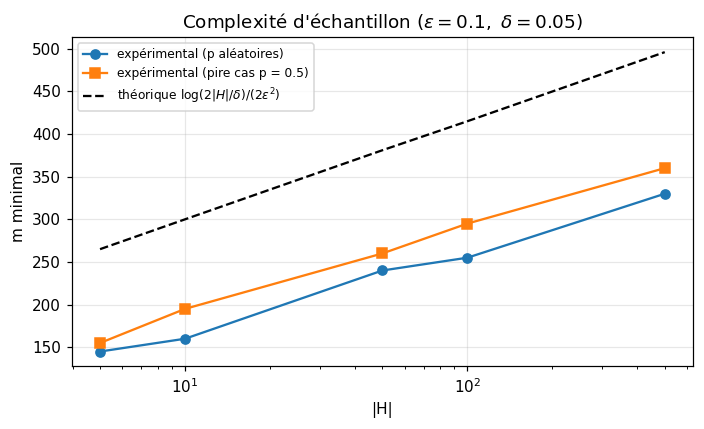

In [6]:
M_FINE = np.arange(5, 601, 5)
R5 = 2_000

def first_m_below_delta(p, R=R5):
    for m in M_FINE:
        if prob_uniform_dev(p, int(m), R=R) <= DELTA:
            return int(m)
    return None

rows = []
for K in K_LIST:
    m_th = int(np.ceil(np.log(2 * K / DELTA) / (2 * EPS ** 2)))
    m_rand  = first_m_below_delta(p_by_K[K])
    m_worst = first_m_below_delta(np.full(K, 0.5))
    rows.append((K, m_rand, m_worst, m_th))

print(f"{'|H|':>5}{'m exp. (p aléatoires)':>24}{'m exp. (p=0.5)':>17}{'m théorique':>14}{'théo/exp (p=0.5)':>19}")
for K, m_r, m_w, m_t in rows:
    print(f"{K:>5}{str(m_r):>24}{str(m_w):>17}{m_t:>14}{m_t / m_w:>19.1f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
Ks = [r[0] for r in rows]
ax.plot(Ks, [r[1] for r in rows], "o-", label="expérimental (p aléatoires)")
ax.plot(Ks, [r[2] for r in rows], "s-", label="expérimental (pire cas p = 0.5)")
ax.plot(Ks, [r[3] for r in rows], "k--", label=r"théorique $\log(2|H|/\delta)/(2\epsilon^2)$")
ax.set_xscale("log"); ax.set_xlabel("|H|"); ax.set_ylabel("m minimal")
ax.set_title(r"Complexité d'échantillon ($\epsilon=0.1,\ \delta=0.05$)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Mon interprétation.**
- La taille théorique est toujours **plus grande** que le $m$ minimal observé, d'un facteur 1.4 à 1.7 dans le pire cas $p_j=0.5$, et de 1.5 à 1.9 pour les risques aléatoires (par exemple $\lvert\mathcal H\rvert=100$ : 255 observé, 415 théorique). C'est cohérent avec une borne **suffisante** : elle garantit que $m$ marche, sans prétendre être le minimum.
- Pourquoi n'est-elle pas exacte ? (1) Hoeffding ignore la variance et vise le pire cas de toutes les lois ; (2) l'union bound additionne les probabilités d'événements qui se recouvrent ; (3) la borne doit tenir pour **toute** configuration de $p_j$ et toute dépendance entre les hypothèses, alors que j'étudie une configuration précise. Une borne valable pour tous les cas ne peut pas être serrée pour chacun.
- La **forme** de la dépendance, elle, est bien reproduite : de $\lvert\mathcal H\rvert=5$ à $500$ (facteur 100), le $m$ théorique augmente de 231 (265 à 496) et le $m$ expérimental du pire cas de 205 (155 à 360). La croissance est donc bien logarithmique en $\lvert\mathcal H\rvert$, avec une pente presque identique.
- Les risques aléatoires demandent un peu moins de données que le pire cas $p=0.5$ car la variance est plus faible pour les $p_j$ éloignés de 0.5.
- Limite : la grille a un pas de 5 et la probabilité est estimée sur 2000 répétitions, donc les valeurs expérimentales sont précises à quelques unités près ; de plus mes hypothèses sont indépendantes, ce qui est une simplification.

# Partie II : simuler le No-Free-Lunch

Domaine fini $\mathcal X = \{1, \dots, N\}$ avec la loi uniforme. À chaque répétition je tire une **nouvelle cible aléatoire** $f(x) \sim \mathrm{Bernoulli}(1/2)$ indépendamment pour chaque $x$, puis un échantillon $S \sim D^m$ (avec répétitions possibles, tirages avec remise). L'étiquette observée en un point $x$ est $f(x)$, donc un point vu deux fois a deux fois la même étiquette.

L'apprenant « par mémorisation » prédit l'étiquette observée si $x$ est dans l'échantillon, et 0 sinon.

In [7]:
def simulate_nfl(N, m, R, unseen_rule="zero", p_f=0.5):
    # R répétitions indépendantes. Renvoie (fraction de points non vus, risque vrai) pour chaque répétition.
    # f(x) ~ Bernoulli(p_f) ; les points vus sont prédits correctement (étiquette observée),
    # les points non vus suivent unseen_rule : 'zero', 'one' ou 'random'.
    f = (rng.random((R, N)) < p_f).astype(np.int8)
    x = rng.integers(0, N, size=(R, m))
    seen = np.zeros((R, N), dtype=bool)
    seen[np.arange(R)[:, None], x] = True

    if unseen_rule == "zero":
        guess = np.zeros((R, N), dtype=np.int8)
    elif unseen_rule == "one":
        guess = np.ones((R, N), dtype=np.int8)
    elif unseen_rule == "random":
        guess = (rng.random((R, N)) < 0.5).astype(np.int8)
    else:
        raise ValueError(unseen_rule)

    pred = np.where(seen, f, guess)             # points vus : étiquette observée = f(x)
    risk = np.mean(pred != f, axis=1)           # L_D(A(S)) sous la loi uniforme
    return 1 - seen.mean(axis=1), risk

## Tâche 6. Points vus et non vus
Pour plusieurs $(N, m)$, j'estime la fraction de points de $\mathcal X$ jamais observés et je la compare à $\left(1 - \frac1N\right)^m$.

**Pourquoi c'est aussi l'espérance de la fraction de points non vus.** Notons $U_x = \mathbf 1[x \text{ n'est jamais tiré}]$. La fraction non vue est $\frac1N\sum_x U_x$, donc son espérance est $\frac1N\sum_x \mathbb E[U_x] = \Pr[x \text{ non vu}]$ par linéarité de l'espérance (les $U_x$ ne sont pas indépendants, mais l'espérance d'une somme n'a pas besoin de cette propriété), et par symétrie cette probabilité est la même pour tous les $x$ : $(1-1/N)^m$.

    m   N=10 sim    théo   N=50 sim    théo  N=100 sim    théo  N=500 sim    théo
    1     0.9000  0.9000     0.9800  0.9800     0.9900  0.9900     0.9980  0.9980
    2     0.8104  0.8100     0.9603  0.9604     0.9801  0.9801     0.9960  0.9960
    5     0.5917  0.5905     0.9041  0.9039     0.9509  0.9510     0.9900  0.9900
   10     0.3451  0.3487     0.8167  0.8171     0.9044  0.9044     0.9802  0.9802
   20     0.1203  0.1216     0.6675  0.6676     0.8182  0.8179     0.9607  0.9608
   50     0.0064  0.0052     0.3627  0.3642     0.6055  0.6050     0.9048  0.9047
  100     0.0000  0.0000     0.1339  0.1326     0.3653  0.3660     0.8187  0.8186
  200     0.0000  0.0000     0.0175  0.0176     0.1348  0.1340     0.6700  0.6701
  500     0.0000  0.0000     0.0000  0.0000     0.0066  0.0066     0.3678  0.3675


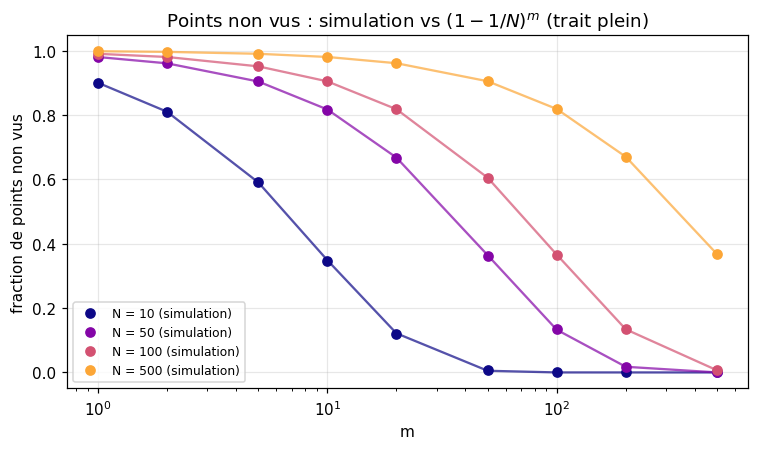

In [8]:
N_LIST = [10, 50, 100, 500]
M_NFL  = [1, 2, 5, 10, 20, 50, 100, 200, 500]
R6 = 2_000

res6 = {N: np.array([simulate_nfl(N, m, R6)[0].mean() for m in M_NFL]) for N in N_LIST}
th6  = {N: (1 - 1 / N) ** np.array(M_NFL) for N in N_LIST}

print(f"{'m':>5}" + "".join(f"{'N='+str(N)+' sim':>11}{'théo':>8}" for N in N_LIST))
for i, m in enumerate(M_NFL):
    print(f"{m:>5}" + "".join(f"{res6[N][i]:>11.4f}{th6[N][i]:>8.4f}" for N in N_LIST))

fig, ax = plt.subplots(figsize=(7, 4.2))
for N, c in zip(N_LIST, plt.cm.plasma(np.linspace(0, 0.8, len(N_LIST)))):
    ax.plot(M_NFL, res6[N], "o", color=c, label=f"N = {N} (simulation)")
    ax.plot(M_NFL, th6[N], "-", color=c, alpha=0.7)
ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_ylabel("fraction de points non vus")
ax.set_title(r"Points non vus : simulation vs $(1-1/N)^m$ (trait plein)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Mon interprétation.** La simulation colle à $(1-1/N)^m$ pour tous les $(N, m)$ (par exemple $N=100$, $m=100$ : 0.3653 simulé contre 0.3660 théorique ; les petits écarts viennent du bruit de Monte-Carlo, surtout quand la valeur est proche de 0). On voit aussi le rôle du rapport $m/N$ : avec $m = N$, il reste environ $1/e \approx 37\,\%$ du domaine non vu ($N=100$, $m=100$), et il faut $m \approx 5N$ pour que la fraction non vue tombe à moins de 1 % ($N=100$, $m=500$ : 0.0066). Pour $N=500$ et $m=100$, **82 % du domaine** n'a jamais été observé : on n'apprend rien sur la grande majorité des points. Le fait que la fraction non vue ne dépend pas de $f$ est cohérent avec la preuve du cours : les points non vus sont ceux sur lesquels aucune étiquette n'a été révélée.

## Tâche 7. Erreur sur les points non vus
Je calcule le vrai risque de l'apprenant par mémorisation $L_D(A(S)) = \frac1N\sum_x \mathbf 1[A(S)(x) \ne f(x)]$ pour de nombreuses cibles aléatoires et échantillons, et je le compare à la prédiction théorique
$$\mathbb E[L_D(A(S))] = \frac12\left(1 - \frac1N\right)^m.$$
**Dérivation.** Les points vus sont toujours bien classés (erreur 0). Pour un point non vu, la prédiction ne dépend pas de $f(x)$, qui est une Bernoulli(1/2) indépendante de l'échantillon : l'erreur vaut donc $1/2$ en espérance, quelle que soit la règle. D'où $\mathbb E[L_D] = \Pr[x\text{ non vu}] \times \tfrac12$.

    N     m  risque sim.  1/2(1-1/N)^m
   20     1       0.4730        0.4750
   20     2       0.4505        0.4512
   20     5       0.3907        0.3869
   20    10       0.2988        0.2994
   20    20       0.1798        0.1792
   20    50       0.0402        0.0385
   20   100       0.0030        0.0030
   20   200       0.0000        0.0000
   20   500       0.0000        0.0000
  100     1       0.4948        0.4950
  100     2       0.4907        0.4900
  100     5       0.4769        0.4755
  100    10       0.4523        0.4522
  100    20       0.4100        0.4090
  100    50       0.3030        0.3025
  100   100       0.1831        0.1830
  100   200       0.0662        0.0670
  100   500       0.0034        0.0033


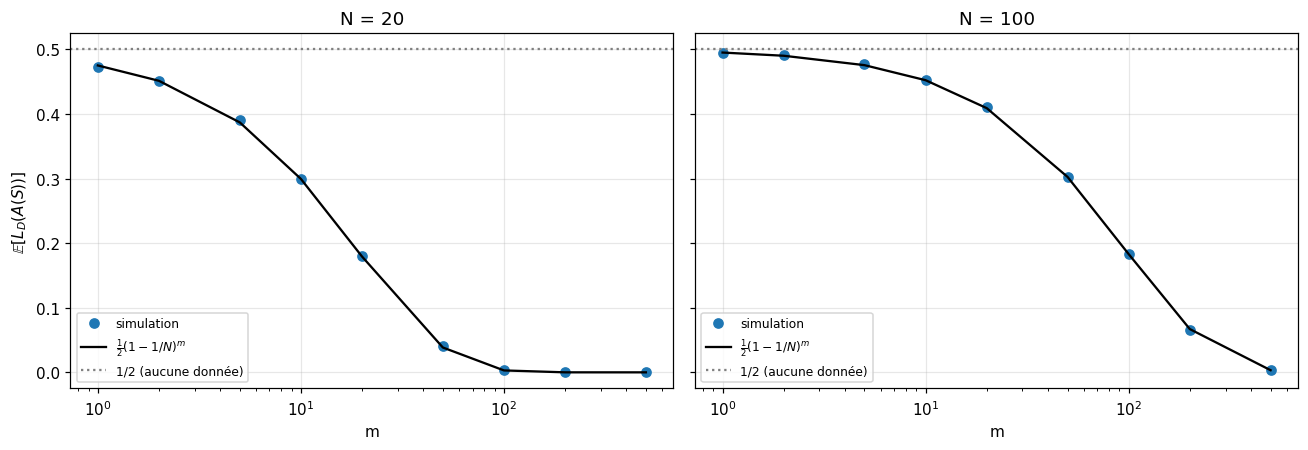

In [9]:
R7 = 2_000
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
print(f"{'N':>5}{'m':>6}{'risque sim.':>13}{'1/2(1-1/N)^m':>14}")
for ax, N in zip(axes, [20, 100]):
    sim = np.array([simulate_nfl(N, m, R7, "zero")[1].mean() for m in M_NFL])
    th  = 0.5 * (1 - 1 / N) ** np.array(M_NFL)
    for m, s, t in zip(M_NFL, sim, th):
        print(f"{N:>5}{m:>6}{s:>13.4f}{t:>14.4f}")
    ax.plot(M_NFL, sim, "o", label="simulation")
    ax.plot(M_NFL, th, "k-", label=r"$\frac{1}{2}(1-1/N)^m$")
    ax.axhline(0.5, color="gray", ls=":", label="1/2 (aucune donnée)")
    ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_title(f"N = {N}"); ax.legend(fontsize=8)
axes[0].set_ylabel(r"$\mathbb{E}[L_D(A(S))]$")
plt.tight_layout(); plt.show()

**Mon interprétation.** Le risque simulé suit la formule $\frac12(1-1/N)^m$ avec un excellent accord (par exemple $N=100$, $m=100$ : 0.1831 contre 0.1830 ; $N=20$, $m=10$ : 0.2988 contre 0.2994). Le risque part de $1/2$ sans donnée, ce qui est la performance d'un tirage à pile ou face, et ne diminue qu'à mesure que le domaine est couvert. Autrement dit, **le risque est entièrement porté par les points non vus** et il est exactement égal à la moitié de leur fraction : sur ces points, les étiquettes sont des pièces non biaisées, donc rien dans l'échantillon ne permet de prédire.

## Tâche 8. Changer la règle sur les points non vus
Je compare trois règles pour les points non vus : toujours 0, toujours 1, ou une étiquette Bernoulli(1/2) aléatoire. Les cibles sont tirées complètement au hasard ($p_f = 1/2$).

Pour illustrer **ce que le théorème suppose vraiment**, j'ajoute une expérience hors énoncé : si les cibles ne sont plus tirées uniformément mais avec $f(x)\sim\mathrm{Bernoulli}(0.9)$ (une connaissance a priori : « la plupart des emails sont du spam »), les règles ne sont plus équivalentes.

Cibles uniformes (p_f = 0.5) : risque moyen
    m      zero       one    random   théorie
    5    0.4757    0.4770    0.4749    0.4755
   20    0.4088    0.4099    0.4091    0.4090
   50    0.3025    0.3037    0.3041    0.3025
  100    0.1840    0.1824    0.1829    0.1830
  200    0.0677    0.0673    0.0675    0.0670

Cibles biaisées (p_f = 0.9) : risque moyen
    m      zero       one    random  théorie 0  théorie 1  théorie rnd
    5    0.8564    0.0959    0.4743     0.8559     0.0951       0.4755
   20    0.7366    0.0822    0.4090     0.7361     0.0818       0.4090
   50    0.5458    0.0600    0.3031     0.5445     0.0605       0.3025
  100    0.3293    0.0370    0.1833     0.3294     0.0366       0.1830
  200    0.1203    0.0136    0.0665     0.1206     0.0134       0.0670


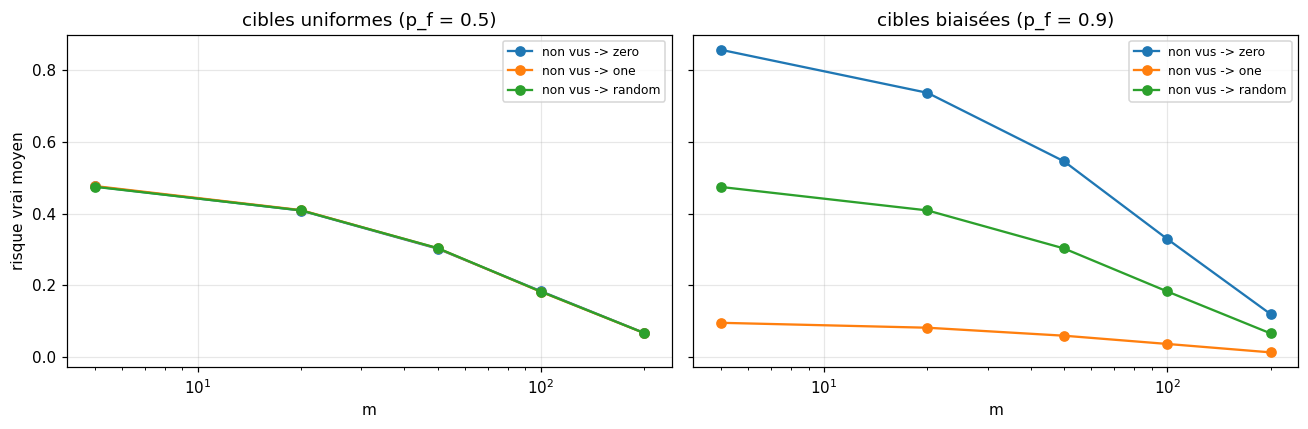

In [10]:
N8, R8 = 100, 3_000
RULES = ["zero", "one", "random"]
M8 = [5, 20, 50, 100, 200]

print("Cibles uniformes (p_f = 0.5) : risque moyen")
print(f"{'m':>5}" + "".join(f"{r:>10}" for r in RULES) + f"{'théorie':>10}")
tab_unif = {}
for m in M8:
    vals = [simulate_nfl(N8, m, R8, r, 0.5)[1].mean() for r in RULES]
    tab_unif[m] = vals
    print(f"{m:>5}" + "".join(f"{v:>10.4f}" for v in vals) + f"{0.5 * (1 - 1 / N8) ** m:>10.4f}")

print("\nCibles biaisées (p_f = 0.9) : risque moyen")
print(f"{'m':>5}" + "".join(f"{r:>10}" for r in RULES) + f"{'théorie 0':>11}{'théorie 1':>11}{'théorie rnd':>13}")
tab_bias = {}
for m in M8:
    vals = [simulate_nfl(N8, m, R8, r, 0.9)[1].mean() for r in RULES]
    tab_bias[m] = vals
    u = (1 - 1 / N8) ** m
    # point non vu : f=1 avec proba 0.9. règle 0 -> erreur 0.9 ; règle 1 -> 0.1 ; règle aléatoire -> 0.5
    print(f"{m:>5}" + "".join(f"{v:>10.4f}" for v in vals) + f"{0.9*u:>11.4f}{0.1*u:>11.4f}{0.5*u:>13.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, tab, title in zip(axes, [tab_unif, tab_bias], ["cibles uniformes (p_f = 0.5)", "cibles biaisées (p_f = 0.9)"]):
    for j, r in enumerate(RULES):
        ax.plot(M8, [tab[m][j] for m in M8], "o-", label=f"non vus -> {r}")
    ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_title(title); ax.legend(fontsize=8)
axes[0].set_ylabel("risque vrai moyen")
plt.tight_layout(); plt.show()

**Mon interprétation.**
- **Cibles uniformes.** Les trois règles donnent le même risque aux erreurs de simulation près (à $m=100$ : 0.1840, 0.1824, 0.1829, théorie 0.1830). **Aucune ne bat systématiquement les autres.** C'est exactement le contenu du No-Free-Lunch : en moyenne sur toutes les cibles possibles, la règle sur les points non vus n'a aucune importance, car chaque étiquette non vue est une pièce équilibrée, et toute règle (même aléatoire) se trompe une fois sur deux dessus.
- **Ce que le théorème suppose.** Dans mon expérience hors énoncé avec $f(x)\sim\mathrm{Bernoulli}(0.9)$, les règles ne sont plus équivalentes : « toujours 1 » donne 0.037 à $m=100$, « aléatoire » 0.183 et « toujours 0 » 0.329 (soit environ 9 fois plus que « toujours 1 »). Ces valeurs correspondent aux prédictions $0.1u$, $0.5u$, $0.9u$ avec $u=(1-1/N)^m$. Une règle gagne donc dès que l'on sait quelque chose sur la distribution des cibles : **connaître ce biais, c'est exactement une connaissance a priori**. Le NFL ne dit pas que l'apprentissage est impossible, il dit qu'un apprenant n'est bon que dans la mesure où ses hypothèses correspondent à la réalité du problème.

# Partie III : introduire une connaissance a priori

Même domaine $\mathcal X = \{1,\dots,N\}$, mais la cible est maintenant un **seuil** $f_\theta(x) = \mathbf 1[x > \theta]$ avec $\theta \in \{1,\dots,N-1\}$ tiré uniformément. L'apprenant utilise l'ERM sur la classe $\mathcal H = \{h_t(x) = \mathbf 1[x > t] : t \in \{1,\dots,N-1\}\}$.

**Implémentation de l'ERM.** Pour chaque $t$, l'erreur empirique vaut (nombre d'exemples $y=1$ avec $x \le t$) + (nombre d'exemples $y=0$ avec $x > t$). Avec deux histogrammes (un par étiquette) et des sommes cumulées, je calcule ces erreurs pour tous les $t$ en $O(N + m)$. En cas d'égalité entre plusieurs seuils (tous ceux qui séparent parfaitement l'échantillon), je prends celui du **milieu** de la liste des minimiseurs : n'importe quel minimiseur est un ERM valide, ce choix évite seulement un biais systématique d'un côté.

Comme $\mathcal X$ est fini et uniforme, le vrai risque se calcule exactement : $L_D(h_t) = \lvert t - \theta\rvert / N$.

In [11]:
def erm_threshold_discrete(x, y, N):
    # x in {1..N}, y in {0,1}. ERM sur H = {h_t : t = 1..N-1}. Renvoie (t_hat, erreur empirique)
    m = len(x)
    c1 = np.bincount(x[y == 1], minlength=N + 1)
    c0 = np.bincount(x[y == 0], minlength=N + 1)
    cum1, cum0 = np.cumsum(c1), np.cumsum(c0)
    t = np.arange(1, N)
    err = cum1[t] + (c0.sum() - cum0[t])            # y=1 prédits 0  +  y=0 prédits 1
    best = t[err == err.min()]
    return int(best[len(best) // 2]), err.min() / m

# Test de cohérence : l'ERM par histogrammes doit donner la même erreur minimale qu'une recherche brute
N_T = 30
for _ in range(200):
    th = rng.integers(1, N_T)
    xs = rng.integers(1, N_T + 1, size=int(rng.integers(1, 40)))
    ys = (xs > th).astype(int)
    if rng.random() < 0.5:                                    # on bruite la moitié des tests
        ys = np.where(rng.random(len(ys)) < 0.2, 1 - ys, ys)
    _, e = erm_threshold_discrete(xs, ys, N_T)
    brute = min(np.mean((xs > t).astype(int) != ys) for t in range(1, N_T))
    assert abs(e - brute) < 1e-12
print("ERM validé contre la recherche exhaustive sur 200 cas.")

ERM validé contre la recherche exhaustive sur 200 cas.


## Tâche 9. Apprendre avec un biais inductif adapté
Pour plusieurs $m$, je tire $\theta$, un échantillon, j'apprends $h_S$ par ERM et je calcule le vrai risque sur tout $\mathcal X$. Je répète 3000 fois et j'estime $\mathbb E[L_D(h_S)]$. Je compare au risque de la Partie II (cibles aléatoires) pour le même $(N, m)$.

In [12]:
def structured_risk(N, m, R):
    risks = np.empty(R)
    for r in range(R):
        theta = rng.integers(1, N)                       # theta in {1..N-1}
        x = rng.integers(1, N + 1, size=m)
        y = (x > theta).astype(int)
        t_hat, _ = erm_threshold_discrete(x, y, N)
        risks[r] = abs(t_hat - theta) / N                # risque vrai exact
    return risks

N9, R9 = 100, 3_000
M9 = [1, 2, 5, 10, 20, 50, 100, 200, 500]
struct9 = np.array([structured_risk(N9, m, R9).mean() for m in M9])
random9 = np.array([simulate_nfl(N9, m, 2000, "zero")[1].mean() for m in M9])
theory9 = 0.5 * (1 - 1 / N9) ** np.array(M9)

print(f"N = {N9}")
print(f"{'m':>5}{'cible seuil + ERM':>19}{'cible aléatoire':>17}{'1/2(1-1/N)^m':>14}{'rapport aléat./seuil':>22}")
for m, s, r_, t in zip(M9, struct9, random9, theory9):
    print(f"{m:>5}{s:>19.4f}{r_:>17.4f}{t:>14.4f}{(r_ / s if s > 0 else float('nan')):>22.1f}")

N = 100
    m  cible seuil + ERM  cible aléatoire  1/2(1-1/N)^m  rapport aléat./seuil
    1             0.1706           0.4957        0.4950                   2.9
    2             0.1245           0.4904        0.4900                   3.9
    5             0.0733           0.4773        0.4755                   6.5
   10             0.0407           0.4529        0.4522                  11.1
   20             0.0224           0.4085        0.4090                  18.2
   50             0.0093           0.3032        0.3025                  32.5
  100             0.0043           0.1831        0.1830                  42.4
  200             0.0014           0.0664        0.0670                  48.9
  500             0.0001           0.0034        0.0033                  50.2


**Mon interprétation.** Avec le biais inductif « la cible est un seuil » et la classe des seuils, le risque chute très vite : à $m=100$ et $N=100$, 0.0043 contre 0.183 pour les cibles aléatoires (environ 42 fois moins), et à $m=20$, 0.022 contre 0.409. À $m=1$ le risque est déjà 0.17 contre 0.50. Le risque structuré décroît à peu près comme $1/(2(m+1))$ tant que $m \ll N$ (par exemple 0.0224 pour $m=20$ contre $1/42 = 0.0238$) : c'est l'ordre de grandeur de la taille de l'intervalle d'incertitude autour de $\theta$ entre deux points voisins de l'échantillon (un argument heuristique que j'ai trouvé cohérent avec les valeurs, pas une preuve). Pour $m$ très grand devant $N$, le risque tend vers 0 puisque $\theta$ est entièrement déterminé. Le rapport entre les deux risques passe de 2.9 à $m=1$ à plus de 40 pour $m \ge 100$ (la valeur exacte à $m=500$, environ 50, est peu précise car le risque structuré vaut alors à peine $10^{-4}$).

## Tâche 10. Cibles aléatoires vs cibles structurées
Je trace l'évolution du vrai risque avec $m$ dans les deux cas, pour deux tailles de domaine ($N = 100$ et $N = 500$), en échelle linéaire puis logarithmique.

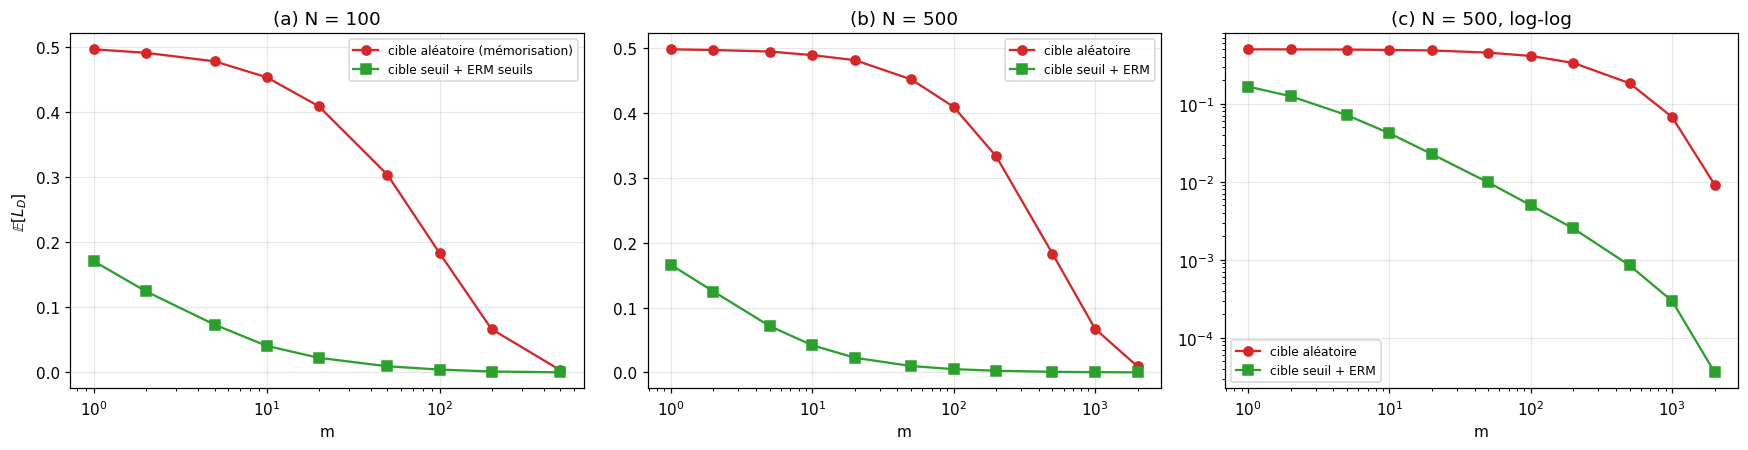

N = 500, m = 100 : aléatoire = 0.410, seuil = 0.0050
N = 500, m = 500 : aléatoire = 0.183, seuil = 0.0008


In [13]:
N10 = 500
M10 = [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000]
struct10 = np.array([structured_risk(N10, m, 1500).mean() for m in M10])
random10 = np.array([simulate_nfl(N10, m, 1000, "zero")[1].mean() for m in M10])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
# (a) N = 100, échelle log-x
ax = axes[0]
ax.plot(M9, random9, "o-", c="tab:red", label="cible aléatoire (mémorisation)")
ax.plot(M9, struct9, "s-", c="tab:green", label="cible seuil + ERM seuils")
ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_ylabel(r"$\mathbb{E}[L_D]$"); ax.set_title(f"(a) N = {N9}"); ax.legend(fontsize=8)
# (b) N = 500
ax = axes[1]
ax.plot(M10, random10, "o-", c="tab:red", label="cible aléatoire")
ax.plot(M10, struct10, "s-", c="tab:green", label="cible seuil + ERM")
ax.set_xscale("log"); ax.set_xlabel("m"); ax.set_title(f"(b) N = {N10}"); ax.legend(fontsize=8)
# (c) échelle log-log, N = 500
ax = axes[2]
ax.loglog(M10, random10, "o-", c="tab:red", label="cible aléatoire")
ax.loglog(M10, np.where(struct10 > 0, struct10, np.nan), "s-", c="tab:green", label="cible seuil + ERM")
ax.set_xlabel("m"); ax.set_title(f"(c) N = {N10}, log-log"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"N = {N10}, m = 100 : aléatoire = {random10[M10.index(100)]:.3f}, seuil = {struct10[M10.index(100)]:.4f}")
print(f"N = {N10}, m = 500 : aléatoire = {random10[M10.index(500)]:.3f}, seuil = {struct10[M10.index(500)]:.4f}")

**Mon interprétation.**
- **Cibles aléatoires** : le risque reste proche de 1/2 tant que $m \ll N$ et ne diminue que lorsque $m$ devient de l'ordre de $N$ : pour $N=500$, il vaut encore 0.41 à $m=100$ et 0.18 à $m=500$. La courbe dépend fortement de $N$ : plus le domaine est grand, plus il faut d'exemples.
- **Cibles seuils** : pour $N=500$, le risque est déjà de 0.005 à $m=100$ et de 0.0008 à $m=500$, soit environ 80 et 230 fois moins. Il dépend très peu de $N$ tant que $m \ll N$ (à $m=100$ : 0.0043 pour $N=100$ et 0.0050 pour $N=500$). L'apprenant généralise donc à plusieurs centaines de points non vus avec une centaine d'exemples.
- **Pourquoi ?** Dans le cas aléatoire, un point non vu ne partage aucune information avec les points vus : sa vraie étiquette est indépendante de l'échantillon. Dans le cas des seuils, **un seul exemple informe sur beaucoup de points** : si $x_i$ est étiqueté 0, tous les $x \le x_i$ le sont aussi, et si $x_j$ est étiqueté 1, tous les $x \ge x_j$ également. Les points non vus à gauche du plus grand point d'étiquette 0 sont forcément 0, et ceux à droite du plus petit point d'étiquette 1 sont forcément 1. Seuls les points situés entre ces deux exemples restent incertains, et cet intervalle est petit.
- **Rôle de l'hypothèse « la cible est un seuil ».** C'est la réalisabilité : elle lie les étiquettes des points non vus à celles des points vus. Sans elle (cible aléatoire), il n'y aurait aucune raison que l'ERM sur les seuils généralise : l'échantillon ne contiendrait aucune structure à exploiter (je n'ai pas simulé ce cas). Avec elle, il y a un seuil qui classe tout l'échantillon parfaitement et la structure de la classe contraint le reste. La classe $\mathcal H$ n'a que $N-1$ éléments pour $2^N$ cibles possibles : c'est cette restriction qui rend l'apprentissage possible.

# Tâche 11. Conclusion

Dans ce devoir, trois expériences se complètent, et ensemble elles montrent à la fois **pourquoi** apprendre est possible et **à quelle condition**.

- **Pourquoi $L_S(h)$ se concentre autour de $L_D(h)$ quand $m$ augmente.** $L_S(h)$ est une moyenne de $m$ variables indépendantes de moyenne $L_D(h)$ : son espérance est exactement $L_D(h)$ et son écart-type vaut $\sqrt{p(1-p)/m}$ (tâche 1). Hoeffding transforme cette idée en une probabilité de grande déviation qui décroît exponentiellement en $m\epsilon^2$ (tâche 2).
- **Pourquoi la convergence uniforme exige un contrôle simultané.** L'ERM choisit son hypothèse à partir du même échantillon qui sert à estimer les risques : il ne suffit donc pas que chaque $L_S(h)$ soit proche de $L_D(h)$ séparément, il faut que ce soit vrai pour **toutes** les hypothèses en même temps, c'est-à-dire contrôler $\Delta_S = \max_h \lvert L_S(h)-L_D(h)\rvert$. Mes simulations le montrent : à $m=100$, la déviation d'une hypothèse isolée dépasse $\epsilon$ dans 3.6 % des cas, mais le maximum sur 50 hypothèses dans 71 % des cas (tâche 3).
- **Comment $\lvert\mathcal H\rvert$ intervient.** Plus la classe est grande, plus il y a de chances qu'une hypothèse « trompeuse » ait un grand écart. La complexité d'échantillon croît **logarithmiquement** avec $\lvert\mathcal H\rvert$ : multiplier la taille de la classe par 100 a augmenté le $m$ nécessaire d'environ 205 sur 155 au départ, soit un facteur 2.3, et non 100 (tâches 4 et 5).
- **Pourquoi les bornes finies sont conservatives.** Elles sont valides pour toutes les lois et toutes les dépendances (pire cas), ignorent la variance (Hoeffding) et additionnent des événements qui se chevauchent (union bound). Mes mesures donnent un facteur 1.4 à 1.9 entre $m$ théorique et $m$ minimal observé, et jusqu'à 8 entre les probabilités à $m$ fixé. Ce sont des **garanties suffisantes**, pas des valeurs exactes.
- **Pourquoi des cibles complètement aléatoires rendent les étiquettes non vues imprévisibles.** Chaque $f(x)$ est une pièce équilibrée indépendante des autres : l'échantillon ne contient aucune information sur les points non vus, dont la fraction vaut $(1-1/N)^m$. Le risque est alors exactement $\frac12(1-1/N)^m$ (tâches 6 et 7).
- **Ce que montre l'expérience No-Free-Lunch.** Aucune des trois règles sur les points non vus ne gagne en moyenne sur les cibles uniformes (0.184, 0.182, 0.183 à $m=100$) : un apprenant ne peut pas déduire les étiquettes arbitraires non observées à partir de l'échantillon seul. Même si chaque tâche admet un classifieur parfait, aucun algorithme ne les résout toutes. Dès qu'on suppose un a priori sur les cibles (ici $p_f=0.9$), une règle devient 9 fois meilleure que l'autre (tâche 8).
- **Comment restreindre cibles et hypothèses aux seuils introduit une connaissance a priori.** La classe des seuils est minuscule ($N-1$ fonctions parmi $2^N$) et elle encode l'hypothèse « les étiquettes sont ordonnées le long de $x$ ». C'est un biais inductif : on renonce à pouvoir apprendre n'importe quelle cible, en échange de la possibilité d'apprendre efficacement celles qui ont cette structure.
- **Pourquoi ce biais permet de généraliser au-delà des exemples observés.** Avec les seuils, chaque exemple apporte de l'information sur toute une moitié du domaine : à $m=100$, $N=100$, le risque est 0.004 au lieu de 0.18, et il reste très stable quand $N$ passe de 100 à 500 (0.0043 contre 0.0050) alors que le risque aléatoire dépend fortement de $N$ (0.18 pour $N=100$ et 0.41 pour $N=500$ à $m=100$) (tâche 10).

**Limites.** Les hypothèses de la partie I sont simulées comme indépendantes (dans un vrai apprentissage elles dépendent du même échantillon), les paramètres ($\epsilon$, $\delta$, $N$) n'ont été variés que sur quelques valeurs, et mes estimations de probabilités sont limitées par le nombre de répétitions (quelques unités de $10^{-4}$ à $10^{-3}$ au mieux).